uomlogo.png

# PHYS20762 - Project 3 - Monte Carlo Techniques

## Neutron Transport and Scattering Through a Shielding Layer

Aidan Hughes
University of Manchester
Feburary 2025

In [ ]:
# setting up notebook
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import pyplot
from time import time

start_time = time() # start timer 

## Testing built in random number generator
### Verifing uniformity and randomness by histogram
First, the uniformity of the random number generator used in this program is tested by plotting values generated in a histogram and then recording the number of bins which are over a single standard deviation from the expected mean value calculated from sample size and number of bins. If uniform, it would be expected that around $68$% of bins would fall within 1 standard deviation, using a normal approximation for the error in distribution of random numbers. 

The code below makes use of numpy.random.uniform() to generate random numbers and numpy.histogram() to sort them into bins. The resulting bins are then plotted matplotlib.bar() to form a bar chart. Boolean arrays are used to determine numbr of bars outside of 1 standard deviation. 

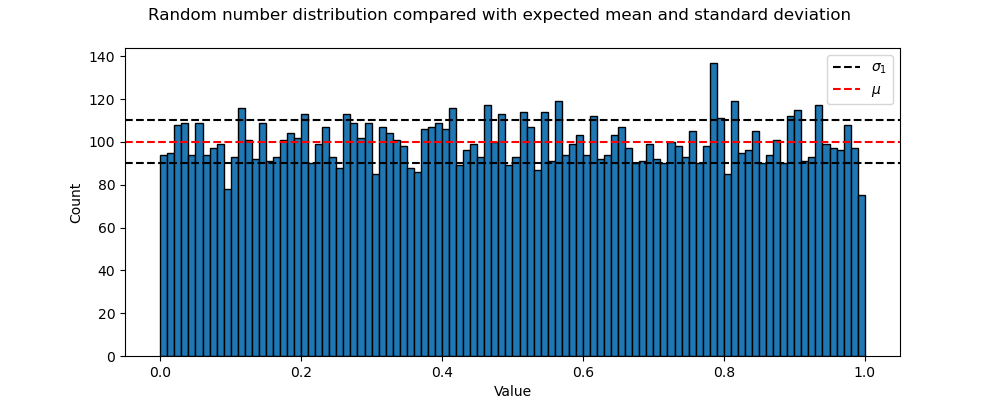

26 bins appear outside of 1 standard deviation, which means 74.0 % are within 1 std compared to the ~68% that should be if modelled as normal distribution.


In [ ]:
def uniform_histogram(sample_size, bin_number):
    bin_mean = sample_size/bin_number # calculated mean bin value
    sample = np.random.uniform(size = sample_size) # creating the random sample
    histogram_array, edge_array = np.histogram(sample, bins=bin_number) # forming bins of random values
    centers = 0.5 * (edge_array[:-1] + edge_array[1:]) # using edges array outputted ot find centers of bins

    # sets figure size, title and subplots
    plt.rcParams["figure.figsize"] = (10,4) 
    fig,(ax1) = plt.subplots(1,1)
    fig.suptitle("Random number distribution compared with expected mean and standard deviation")

    # plots bar graph of the histogram calculated
    ax1.bar(centers, histogram_array, width=edge_array[1]-edge_array[0], edgecolor='k')
    # name axis
    ax1.set_xlabel('Value')
    ax1.set_ylabel('Count')
    # plot mean and 1sd lines
    ax1.axhline(bin_mean - np.sqrt(bin_mean), color='k', linestyle='--', label = r'$\sigma_1$')
    ax1.axhline(bin_mean + np.sqrt(bin_mean), color='k', linestyle='--')
    ax1.axhline(bin_mean, color='r', linestyle='--', label=r'$\mu$')
    # shows fig and legend
    plt.legend()
    plt.show()
    # calculates bars outside 1sd
    plus_1_std = histogram_array > (bin_mean + np.sqrt(bin_mean))
    minus_1_std = histogram_array < (bin_mean - np.sqrt(bin_mean))
    out_1_std = minus_1_std.sum() + plus_1_std.sum()
    # outputs
    print(out_1_std, r"bins appear outside of 1 standard deviation, which means", (1 - out_1_std/bin_number)*100,'%',
          r"are within 1 std compared to the ~68% that should be if modelled as normal distribution.")
    return None

uniform_histogram(10000, 100)

The graph above shows randomness and uniformity, atleast in one demension. However, it does not completely prove those properties. To do so more tests are done.

### Spectral test of random numbers in three dimensions

Some methods used to generate random numbers result in apparent randomness when observing in lower dimensions, such as one or two, but have clear patterns in higher dimensions. To test, 3 sets of numpy.random.uniform() are generated and plotted as the x, y and z co-ordinates in a scatter plot. Then the points can be checked for visual tells of non random sequencing between points, as they will appear as patterns from some angles. Also plotted is three sets of randssp, a random number generator used by IBM, which has the spectral issues being looked for to compare against. 

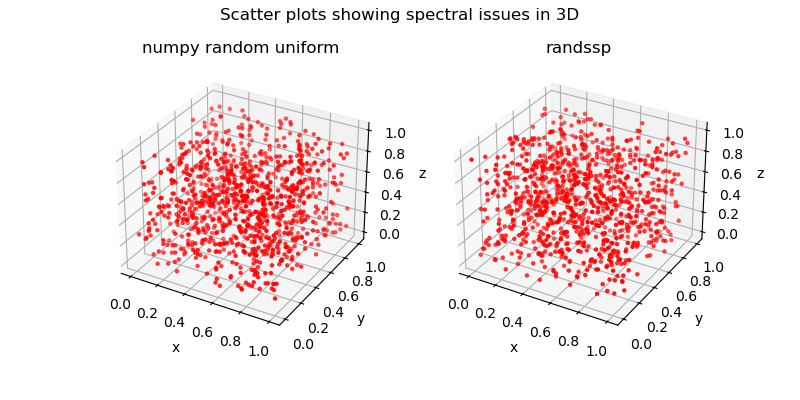

In [ ]:
def plot_3D(val_array, plot_number, plot_title, plot_x=1, plot_y=1):
    # sets subplots
    ax = fig.add_subplot(plot_y, plot_x, plot_number, projection='3d')
    # plots 3D scatter
    ax.scatter(val_array[0, :], val_array[1, :], val_array[2, :], marker ='.' ,color='r')
    # name axis and subplot title
    ax.set_title(plot_title)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')
    return None

def randssp(p,q):
    
    global m, a, c, x
        
    try: x
    except NameError:
        m = pow(2, 31)
        a = pow(2, 16) + 3
        c = 0
        x = 123456789
    
    try: p
    except NameError:
        p = 1
    try: q
    except NameError:
        q = p
    
    r = np.zeros([p,q])

    for l in range (0, q):
        for k in range (0, p):
            x = np.mod(a*x + c, m)
            r[k, l] = x/m
    
    return r


SIZE_SPECTRAL = 1000 # size of random data used

%matplotlib ipympl 
# import interactive plot magic

# sets figure size and title
plt.rcParams["figure.figsize"] = (8,4)
fig = plt.figure()
plt.suptitle("Scatter plots showing spectral issues in 3D")

# produces the 2 3D arrays for plotting
numpy_array = np.array([np.random.uniform(size = SIZE_SPECTRAL),np.random.uniform(size = SIZE_SPECTRAL),np.random.uniform(size = SIZE_SPECTRAL)])
randssp_array = randssp(3, SIZE_SPECTRAL)

# plots the 3D arrays
plot_3D(numpy_array, 1, "numpy random uniform",2)
plot_3D(randssp_array, 2, "randssp",2)

plt.show()

When the randssp plot is viewed from the negetive z direction, the points seem to be arranged into lines. This is because all the random numbers generated by the randssp method lie on hyperplanes when plotted in three dimentions. This is due to a flaw in the method of generation which leads to a strong linear correlation between 3 successive values. This makes it wildly unsutable for applications in 3 or more dimensions, including a 3D Monte Carlo integration, as it will give biased results along the hyperplanes. However it can still be used in 1 and 2 dimensional problems aslong as the face used is near perpendicular to the hyperplanes. 

However the numpy.random.uniform does not show such properties as on visual inspection it appears random in 3 dimensions. This means it is suitable for applications in 3 dimensions, however not proven for higher dimensions. 

## Preparing for full simulation
### Absorption attenuation length of water
To find the absorption attenuation length of water, the absorption cross section is calculated using given values for thermal neutrons. This value is then used to produce an array of random numbers distributed by $e^{-x\sigma_a}$, where $\sigma_a$ is the absorption cross-section. This is done by generating uniform random numbers and then inputting them into the inverse of the CDF.  The formula for the exponentially distributed values is $$y = -\frac{1}{\sigma_a}\ln(x)$$ where $x$ is a uniform distribution from 0 to 1. These values are then placed into bins using numpy.histogram and bins with no counts in are removed. The count value of the bins in then logged and plotted against the distance value asscociated with the bin. This is gives a linear fit and numpy.polyfit is used to find the gradient as well as weighting the points according to the reciporical of their uncertainty. The uncertainty for the points is approximated to $1/\sqrt{C}$ where $C$ is the count. The attenuation length can then be found $$\lambda_a = -\frac{1}{m}$$ where $m$ is the gradient.

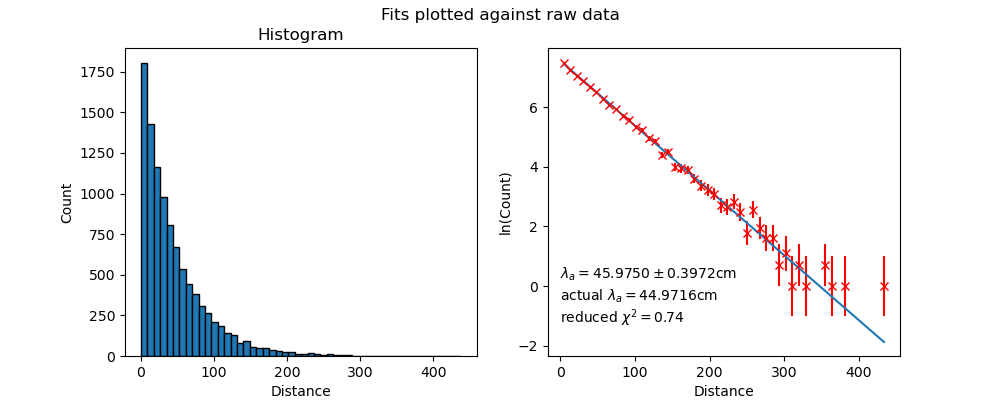

In [ ]:
AVAGADRO = 6.02214076e23 
water_absorption_lambda = 1/(0.6652*1/18.0153*AVAGADRO*10**(-24)) # in cm
DATA_SIZE = 10000 # data size used


def exp_rand(mean_free_path, sample_size=DATA_SIZE):
    rand_uniform = np.random.uniform(size = sample_size) # generates uniform rand number set
    return -mean_free_path*np.log(rand_uniform) # acts inverse CDF to get exponential distribution


def clean_data(raw_data):
    isnt_zero = raw_data[:,1] > 0 # creates boolean array which is true for non zero data 
    return raw_data[isnt_zero, :] # removes zero data


def histogram_polyfit(exp_data, bin_number):

    histogram_array, edge_array = np.histogram(exp_data, bins=bin_number) # forming bins of exponential random values
    centers = 0.5 * (edge_array[:-1] + edge_array[1:])# using edges array outputted ot find centers of bins

    # sets figure size, title and subplots
    plt.rcParams["figure.figsize"] = (10,4)
    fig,(ax1,ax2) = plt.subplots(1,2)
    fig.suptitle("Fits plotted against raw data")

    # plots bar graph, labels sub plot and axis
    ax1.bar(centers, histogram_array, width=edge_array[1]-edge_array[0], edgecolor='k')
    ax1.set_title("Histogram")
    ax1.set_xlabel('Distance')
    ax1.set_ylabel('Count')
    
    # calculates log values and performs linear best fit
    clean_histogram = clean_data(np.column_stack([centers, histogram_array]))
    log_histogram = np.log(clean_histogram[:, 1])
    coef, covr = np.polyfit(clean_histogram[:, 0], log_histogram, 1, w=np.sqrt(clean_histogram[:,1]), cov =True)
    # finds chi2 value and attenuation length and error
    atten_fit = np.polyval(coef, clean_histogram[:, 0])
    fitted_lambda = -1/coef[0]
    err_lambda = np.sqrt(covr[0,0])/((coef[0])**2)
    chi_2d = chi_squared(atten_fit, log_histogram, 1/(np.sqrt(clean_histogram[:,1]))) 
    chi_red = chi_2d/(len(log_histogram)-2)
    # plots log line graph, labels sub plot and axis
    ax2.errorbar(clean_histogram[:,0], log_histogram,yerr=1/(np.sqrt(clean_histogram[:,1])), fmt = 'x', color = 'r')
    ax2.plot(clean_histogram[:,0], atten_fit, '-', label='fit')
    ax2.set_xlabel('Distance')
    ax2.set_ylabel('ln(Count)')
    # text to show values of fit and chi
    ax2.text(0,0.25, r'$\lambda_a = {:.4f} \pm {:.4f}$cm'.format(fitted_lambda, err_lambda))
    ax2.text(0,-0.5, r'actual $\lambda_a = {:.4f}$cm'.format(water_absorption_lambda))
    ax2.text(0,-1.25, r'reduced $\chi^2 = {:.2f}$'.format(chi_red))
    plt.show()
    
    return None


def chi_squared(y_fit, y_data, y_uncertainties):
    #takes in y_fit, y_data and y_uncertainties
    #outputs the repesctive chi squared
    return np.sum((y_fit - y_data)**2 / y_uncertainties**2)


histogram_polyfit(exp_rand(water_absorption_lambda), 50)

A data set $10000$ in size was used to produce the above graphs. The value of $\lambda_a$ is close to the actual value of $44.97$cm determined from $$\lambda_a = \frac{1}{\sigma_a}$$ and is useful to prove that this is an adequet method of finding attenuation length for the future when there isnt an analytical solution it. The reduced $\chi^2$ is also reasonable, verifying that a linear fit is correct and the uncertainties approximation of a normal distribution is suitable. The uncertainty on $\lambda_a$ was given by the numpy.polyfit. 
### Producing isotropic unit vectors
The isotropic unit vectors are produced using numpy.random.uniform along with polar co-ordinates. The $\phi$ values are generated uniformly between $-\pi$ and $\pi$. However,to avoid any clumping at the tops of the sphere causing it to cease being isotropic, the $\theta$ values are generated using $$\theta = \arccos\left(1-2N\right)$$ where $N$ are uniform random numbers between 0 and 1. The poles occur as the circumfrence of a slice of the spherical shell decreases as $\theta$ approaches $0$ and $\pi$. The polar values are then converted to cartesian coordinates with $r=1$ to make it a unit vector and plotted to check for pole errors.

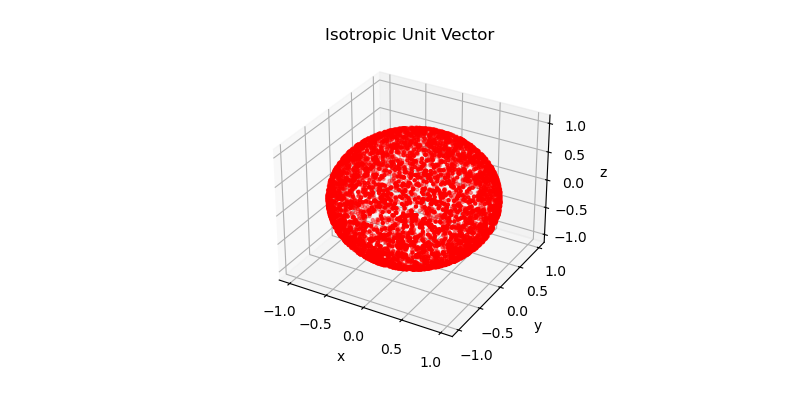

In [ ]:
def isotropic_unit_vector(sample_size=1):
    phi = np.random.uniform(low = -np.pi, high = np.pi, size=sample_size) # produced random uniform values -pi to pi
    theta = np.arccos(1-2*np.random.uniform(size=sample_size)) # uses inverse CDF to produce theta values that wont pole
    # convert to cartesian co ordinates
    sin_theta = np.sin(theta)
    x = sin_theta*np.cos(phi)
    y = sin_theta*np.sin(phi)
    z = np.cos(theta)
    return np.array([x, y, z]) # output as 2D array 

# sets figure size
plt.rcParams["figure.figsize"] = (8,4)
fig = plt.figure()

plot_3D(isotropic_unit_vector(5000),1,"Isotropic Unit Vector")

plt.show()

The plotted hollow sphere has no visible poles, meaning it is isotropic so can be used to help model the random walks. 

### Simple random walk

By combining the exponential random number generator and the isotropic unit vectors, a series of steps in random direction and length can be produced. When added in sequence, this forms a random walk. 

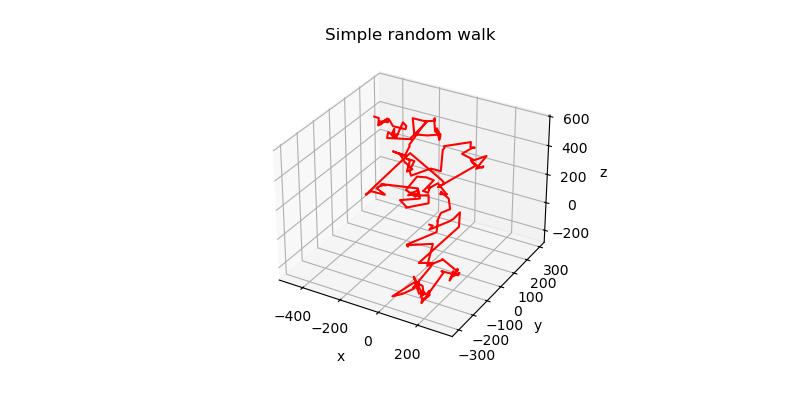

In [ ]:
def step_function(mean_free_path, step_number):
    position = np.array([exp_rand(mean_free_path, 1)[0], 0, 0]) # forces first step in +x direction
    pos_array = np.zeros([3,step_number+2]) # empty array to store path history in
    pos_array[:, 1] = position[:]
    i = 0
    while step_number > i:
        position = position + isotropic_unit_vector(1)[:,0]*exp_rand(mean_free_path, 1)[0] # updates position by adding step
        pos_array[:, i+2] = position[:] # records position in array to be plotted
        i += 1
    return np.transpose(pos_array)


def plot_path_3D(val_array, plot_number, plot_title, plot_x=1, plot_y=1):
    # plot random walk
    ax = fig.add_subplot(plot_y, plot_x, plot_number, projection='3d')
    ax.plot(val_array[:, 0], val_array[:, 1], val_array[:, 2], color='r')
    # set title and axis label
    ax.set_title(plot_title)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')

    return None

# sets figure size
plt.rcParams["figure.figsize"] = (8,4)
fig = plt.figure()

plot_path_3D(step_function(water_absorption_lambda, 200), 1, "Simple random walk")

plt.show()

## Simulating Neutron Travel 
### Calculating Total Mean Free Path
Neutrons travelling through a material can either be absorped or scattered by the material they are travelling through. Each  molecule of a material has an absorption ($\sigma_a$) and a scattering ($\sigma_s$) cross-section which is an area that if hit by a thermal neutron, will cause the molecule to absorb or scatter that neutron. To get the cross-sections of the material, the macroscopic cross-sections, $$\Sigma_{a/s} = N\sigma_{a/s} = \frac{\rho}{M}A\sigma_{a/s}$$ where $N$ is the number density, $\rho$ is mass density, $M$ is molar mass and $A$ is Avagadros constant. The total mean free path, the average distance before meeting a molecule of the material, is given as $\lambda_T = \frac{1}{\Sigma_{a}+\Sigma_{s}}$. These values are calculated below.

In [ ]:
N_water = 1/18.0153*AVAGADRO # in cm^-3
water_absorption_xs = 0.6652*N_water*10**(-24) # in cm^-1
water_scattering_xs = 103.0*N_water*10**(-24) # in cm^-1
water_total_mfp = 1/(water_absorption_xs + water_scattering_xs) # in cm
water = np.array([water_absorption_xs, water_scattering_xs, water_total_mfp]) # in array for easier call

N_lead = 11.35/207.2*AVAGADRO # in cm^-3
lead_absorption_xs = 0.158*N_lead*10**(-24) # in cm^-1
lead_scattering_xs = 11.221*N_lead*10**(-24) # in cm^-1
lead_total_mfp = 1/(lead_absorption_xs + lead_scattering_xs) # in cm
lead = np.array([lead_absorption_xs, lead_scattering_xs, lead_total_mfp])

N_graphite = 1.67/12.011*AVAGADRO # in cm^-3
graphite_absorption_xs = 0.0045*N_graphite*10**(-24) # in cm^-1
graphite_scattering_xs = 4.74*N_graphite*10**(-24) # in cm^-1
graphite_total_mfp = 1/(graphite_absorption_xs + graphite_scattering_xs) # in cm
graphite = np.array([graphite_absorption_xs, graphite_scattering_xs, graphite_total_mfp])

### Visualising Neutron Random Walk
Next a random neutron walk is visualised using the total mean free path of the material to form an random exponential distribution for the inital step in the x direction. By tracking wether a neutron is alive and killing it when it is absorbed or leaves the material, multiple can be simulated at the same time. The position is constantly updated but a position history is kept to be plotted when it is killed. After the initial step, the process of moving a random step size and direction, then checking for leaving the slab or absorption is looped as long as a neutron is alive. 

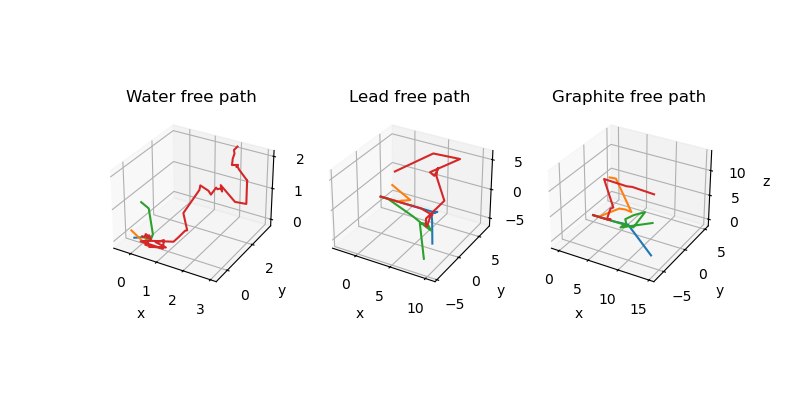

In [ ]:
def vectorised_free_walk_visual(material, plot_title, length,  plot_number, neutron_number = 1):
    # sets subplots
    ax = fig_fwv.add_subplot(1, 3, plot_number, projection='3d')
    # expands out array into local variables for faster calling
    absorp_xs, scatter_xs, mean_free_path = material
    # pre calculates absorption probability 
    prob_absorp = absorp_xs*mean_free_path 
    # set title and axis label
    ax.set_title(plot_title)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('z')
    
    
    alive = np.ones(neutron_number, bool) # creates boolean array of all neutrons which = True as all alive
    
    position = np.zeros((neutron_number, 3)) # sets initial position for all neutrons to 0,0,0
    
    # sets initial direction as 1,0,0 
    initial_direction = np.array([np.ones(neutron_number), np.zeros(neutron_number), np.zeros(neutron_number)])
    
    # bulk calls exp rand function to make array of step sizes
    initial_step = np.transpose(exp_rand(mean_free_path, neutron_number) * initial_direction)

    position_history = np.append(position, initial_step) # adds to array to track path that is being walked to be plotted

    position += initial_step # updates position for the first step

    transmit = position[:] > length # checks if any have left by creating boolean array
    if transmit.any(): # only acts if transmit is not empty
        index_killed = transmit.nonzero()[0] # creates array of indexs of neutrons transmitted
        alive[index_killed] = False # sets alive to false for these neutron indexes
        for index in index_killed: 
            # plots position history for neutrons killed
            ax.plot(position_history[(3*index)::(3*neutron_number)],
                    position_history[(3*index)+1::(3*neutron_number)],position_history[(3*index)+2::(3*neutron_number)])

    index_alive = alive.nonzero()[0] # creates array of index of remaining neutrons
    remaining_number = index_alive.size # counts number remaining
    
    absorp_rand = np.random.uniform(size=remaining_number) # creates random number for each neutron remaining
    absorbed = absorp_rand < prob_absorp # if number less than absorption probability, is true in absorbed array

    if absorbed.any(): # only acts if absorbed is not empty
        index_killed = index_alive[absorbed] # creates array of indexs of neutrons absorbed
        alive[index_killed] = False # sets alive to false for these neutron indexes
        for index in index_killed:
            # plots position history for neutrons killed
            ax.plot(position_history[(3*index)::(3*neutron_number)],
                    position_history[(3*index)+1::(3*neutron_number)],position_history[(3*index)+2::(3*neutron_number)])
    while alive.any(): # checks if there are still some alive neutrons
        index_alive = alive.nonzero()[0] # creates array of index of remaining neutrons
        number_alive = index_alive.size # counts number remaining
        
        step_size = exp_rand(mean_free_path, number_alive) # generates step size for all neutrons alive
        step_direction = isotropic_unit_vector(number_alive) # generates step direction for all neutrons alive
        step = np.transpose(step_direction*step_size) # creates step
        
        position[index_alive] = position[index_alive] + step # updates position index for alive neutrons
        position_history = np.append(position_history, position) # adds to array to track path that is being walked to be plotted

        backscatter = position[index_alive, 0] < 0 # checks if any backscattered
        transmit = position[index_alive, 0] > length # checks if any are transmitted
        
        if backscatter.any(): # only acts if backscatter is not empty
            index_killed = index_alive[backscatter] # creates array of indexs of neutrons backscatted
            alive[index_killed] = False # sets alive to false for these neutron indexes
            for index in index_killed:
                # plots position history for neutrons killed
                ax.plot(position_history[(3*index)::(3*neutron_number)],
                        position_history[(3*index)+1::(3*neutron_number)],position_history[(3*index)+2::(3*neutron_number)])
        
        if transmit.any(): # only acts if transmit is not empty
            index_killed = index_alive[transmit] # creates array of indexs of neutrons transmitted
            alive[index_killed] = False # sets alive to false for these neutron indexes
            for index in index_killed:
                # plots position history for neutrons killed
                ax.plot(position_history[(3*index)::(3*neutron_number)],
                        position_history[(3*index)+1::(3*neutron_number)],position_history[(3*index)+2::(3*neutron_number)])

        escaped = backscatter + transmit # array of neutrons that escaped
        remaining_index = index_alive[~escaped] # removes escpaed neutrons from index array
        remaining_number = remaining_index.size # counts number remaining
        
        absorp_rand = np.random.uniform(size=remaining_number) # creates random number for each neutron remaining
        absorbed = absorp_rand < prob_absorp # if number less than absorption probability, is true in absorbed array
        if absorbed.any(): # only acts if absorbed is not empty
            index_killed = remaining_index[absorbed] # creates array of indexs of neutrons absorbed
            alive[index_killed] = False # sets alive to false for these neutron indexes    
            for index in index_killed:
                # plots position history for neutrons killed
                ax.plot(position_history[(3*index)::(3*neutron_number)],
                        position_history[(3*index)+1::(3*neutron_number)],position_history[(3*index)+2::(3*neutron_number)])

plt.rcParams["figure.figsize"] = (8,4)
fig_fwv = plt.figure()

vectorised_free_walk_visual(water, "Water free path", 10,  1, 4)
vectorised_free_walk_visual(lead,"Lead free path", 10,  2, 4)
vectorised_free_walk_visual(graphite, "Graphite free path",10,  3, 4)
plt.show()

The visualised walks, which use a slab thickness of $10$cm, show that water is more likely to backscatter compared to graphite which is more likely to transmitt neutrons. Also confirms the paths are still random and isotropic. 

### Quantifying Scattering Processes

To quantify the process, only the outcome is recorded rather than the whoel histroy, but it is run for 10000 neutrons 10 times per length per material so uncertainties can be calculated and anomolous runs dont massively affect data. To speed up the code, the slab is assumed infinte in y and z directions, allowing the isotropic vector generator to only form and feed back the x co ordinates of the direction. The average number backscattered, absorbed and transmitted is outputted. The values for 10cm of water are displayed below. 

In [ ]:
SAMPLE_SIZE = 10000
def isotropic_x_vector(sample_size=1):
    # as assumed infinite in y and z only x needed
    theta = np.arccos(1-2*np.random.uniform(size=sample_size)) # uses inverse CDF to produce theta values that wont pole
    x = np.cos(theta) # use formula conventional z as reduced random number generation
    return x

def vectorized_neutron_outcome_counter(material, length, neutron_number = 1):
    # see visualised walk for commented version
    N_absorbed = N_backscatter = N_transmit = 0 # set number of each outcome to 0
    absorp_xs, scatter_xs, mean_free_path = material
    prob_absorp = absorp_xs*mean_free_path

    alive = np.ones(neutron_number, bool)
    position = np.zeros(neutron_number)
    
    initial_direction = np.ones(neutron_number)
    initial_step = exp_rand(mean_free_path, neutron_number) * initial_direction
    
    position = position + initial_step
    transmit = position[:] > length
    if transmit.any():
        index_killed = transmit.nonzero()[0]
        N_transmit += transmit.sum() # add one to count
        alive[index_killed] = False
    index_alive = alive.nonzero()[0]
    remaining_number = index_alive.size
    absorp_rand = np.random.uniform(size=remaining_number)
    absorbed = absorp_rand < prob_absorp
    if absorbed.any():
        index_killed = index_alive[absorbed]
        N_absorbed += absorbed.sum()
        alive[index_killed] = False

    while alive.any():
        index_alive = alive.nonzero()[0]
        number_alive = index_alive.size
        
        step_size = exp_rand(mean_free_path, number_alive)
        step_direction = isotropic_x_vector(number_alive)
        step = step_direction*step_size
        position[index_alive] = position[index_alive] + step

        backscatter = position[index_alive] < 0
        transmit = position[index_alive] > length

        if backscatter.any():
            index_killed = index_alive[backscatter]
            N_backscatter += backscatter.sum() # add one to count
            alive[index_killed] = False
        
        if transmit.any():
            index_killed = index_alive[transmit]
            N_transmit += transmit.sum()
            alive[index_killed] = False
        
        escaped = backscatter + transmit
        remaining_index = index_alive[~escaped]
        remaining_number = remaining_index.size
        absorp_rand = np.random.uniform(size=remaining_number)
        absorbed = absorp_rand < prob_absorp
        if absorbed.any():
            index_killed = remaining_index[absorbed]
            N_absorbed += absorbed.sum()
            alive[index_killed] = False
    return np.array([N_absorbed, N_backscatter, N_transmit])      

def produce_values(material, length_range, repeats, count_function=vectorized_neutron_outcome_counter):
    # runs values over lengths for 10 repeats and outputs
    length_length = len(length_range)
    absorption_array = np.zeros((length_length, 2))
    backscatter_array = np.zeros((length_length, 2))
    transmission_array = np.zeros((length_length, 2))
    for length in length_range:
        length_index = np.where(length_range==length)
        repeats_array = np.zeros((repeats, 3))
        for i in range(repeats):
            repeats_array[i,:] = count_function(material, length, SAMPLE_SIZE)
        (absorption_array[length_index, 0], backscatter_array[length_index, 0], 
         transmission_array[length_index, 0]) = repeats_array.mean(axis = 0)
        (absorption_array[length_index, 1], backscatter_array[length_index, 1], 
         transmission_array[length_index, 1]) = np.sqrt(np.var(repeats_array, axis = 0)) #+ (np.sqrt(repeats_array)).mean(axis = 0)
    return absorption_array, backscatter_array, transmission_array

length_range = np.arange(1,20,1)

start_vectorized = time() # start timer for vectorized code
water_abs, water_back, water_trans = produce_values(water, length_range, 10)
lead_abs, lead_back, lead_trans = produce_values(lead, length_range, 10)
graphite_abs, graphite_back, graphite_trans = produce_values(graphite, length_range, 10)

end_vectorized = time() # end timer for vectorized code

print("Vectorized code took", end_vectorized - start_vectorized, "seconds to run")

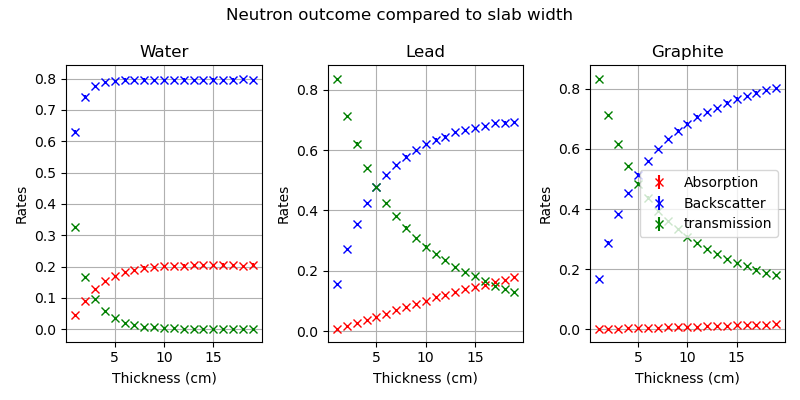

In [ ]:
def plot_material(rate_abs, rate_back, rate_trans, plot_number, length_range, plot_title):
    # plots different materials
    ax = fig_rates.add_subplot(1, 3, plot_number)
    ax.set_title(plot_title)
    ax.set_xlabel('Thickness (cm)')
    ax.set_ylabel('Rates')
    ax.grid()

    
    ax.errorbar(length_range, rate_abs[:, 0]/SAMPLE_SIZE, yerr = rate_abs[:, 1]/SAMPLE_SIZE, fmt ='x' ,color='r', label='Absorption')
    ax.errorbar(length_range, rate_back[:, 0]/SAMPLE_SIZE, yerr = rate_back[:, 1]/SAMPLE_SIZE, fmt ='x' ,color='b', label='Backscatter')
    ax.errorbar(length_range, rate_trans[:, 0]/SAMPLE_SIZE, yerr = rate_trans[:, 1]/SAMPLE_SIZE, fmt ='x' ,color='g',label='transmission') 
    return None


plt.rcParams["figure.figsize"] = (8,4)
fig_rates = plt.figure()   


plot_material(water_abs, water_back, water_trans, 1, length_range, "Water")
plot_material(lead_abs, lead_back, lead_trans, 2, length_range, "Lead")
plot_material(graphite_abs, graphite_back, graphite_trans, 3, length_range, "Graphite")

plt.suptitle("Neutron outcome compared to slab width")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
def non_vectorized_neutron_outcome_counter(material, length, neutron_number = 1):
    # see visualised walk for commented version
    N_absorbed = N_backscatter = N_transmit = 0 # set number of each outcome to 0
    absorp_xs, scatter_xs, mean_free_path = material
    prob_absorp = absorp_xs*mean_free_path

    for n in range(neutron_number):
        position = np.array([0, 0, 0]) # sets initial position to 0,0,0
        alive = True
        while alive:
            step_size = exp_rand(mean_free_path, 1)[0]
            step_direction = isotropic_unit_vector(1)[0]
            step = step_direction*step_size
            position += step

            if position[0] < 0 or position[1] < 0 or position[2] < 0:
                N_backscatter += 1
                alive = False
            elif position[0] > length:
                N_transmit += 1
                alive = False
            else:
                absorp_rand = np.random.uniform(size=1)[0]
                if absorp_rand < prob_absorp:
                    N_absorbed += 1
                    alive = False
    return np.array([N_absorbed, N_backscatter, N_transmit])

start_non_vectorized = time() # start timer for non-vectorized code
water_abs, water_back, water_trans = produce_values(water, length_range, 10, count_function=non_vectorized_neutron_outcome_counter)
lead_abs, lead_back, lead_trans = produce_values(lead, length_range, 10, count_function=non_vectorized_neutron_outcome_counter)
graphite_abs, graphite_back, graphite_trans = produce_values(graphite, length_range, 10, count_function=non_vectorized_neutron_outcome_counter)

end_non_vectorized = time() # end timer for non-vectorized code
print("Non-vectorized code took", end_non_vectorized - start_non_vectorized, "seconds to run")
print("Absolute speedup of vectorized code over non-vectorized code:", end_non_vectorized - start_non_vectorized - (end_vectorized - start_vectorized), "seconds")
print("Percent speedup of vectorized code over non-vectorized code:", (end_non_vectorized - start_non_vectorized)/(end_vectorized - start_vectorized)*100, "%")

In [ ]:
print("      Neutron values for 10cm of water")
print("--------------------------------------------")
print(r"     Number absorbed = {:.1f} +/- {:.1f}".format(water_abs[9, 0], water_abs[9, 1]))
print(r"Number backscattered = {:.1f} +/- {:.1f}".format(water_back[9, 0], water_back[9,1]))
print(r"  Number transmitted = {:.1f}   +/- {:.1f}".format(water_trans[9, 0], water_trans[9,1]))
print(r"    Rate transmitted = {:.2e} +/- {:.1e}".format(water_trans[9, 0]/10000,  water_trans[9,1]/10000))


      Neutron values for 10cm of water
--------------------------------------------
     Number absorbed = 2001.3 +/- 33.9
Number backscattered = 7965.7 +/- 35.7
  Number transmitted = 33.0   +/- 6.0
    Rate transmitted = 3.30e-03 +/- 6.0e-04


The number transmitted is really low and backscattered is high as water has a huge scattering cross section so the mean free path ends up being small. This suggests water would be a great neutron shield. 
### Plotting Variations
By varying slab length for each material and plotting the rates of all three outcomes agaisnt it, trends in the rate can be qualitively determined. The slab length is varied from 1 to 20 cm and plotted below. 

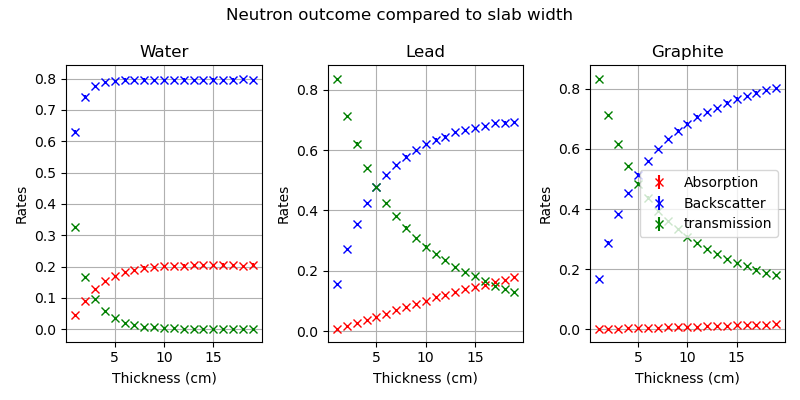

In [ ]:
def plot_material(rate_abs, rate_back, rate_trans, plot_number, length_range, plot_title):
    # plots different materials
    ax = fig_rates.add_subplot(1, 3, plot_number)
    ax.set_title(plot_title)
    ax.set_xlabel('Thickness (cm)')
    ax.set_ylabel('Rates')
    ax.grid()

    
    ax.errorbar(length_range, rate_abs[:, 0]/SAMPLE_SIZE, yerr = rate_abs[:, 1]/SAMPLE_SIZE, fmt ='x' ,color='r', label='Absorption')
    ax.errorbar(length_range, rate_back[:, 0]/SAMPLE_SIZE, yerr = rate_back[:, 1]/SAMPLE_SIZE, fmt ='x' ,color='b', label='Backscatter')
    ax.errorbar(length_range, rate_trans[:, 0]/SAMPLE_SIZE, yerr = rate_trans[:, 1]/SAMPLE_SIZE, fmt ='x' ,color='g',label='transmission') 
    return None


plt.rcParams["figure.figsize"] = (8,4)
fig_rates = plt.figure()   


plot_material(water_abs, water_back, water_trans, 1, length_range, "Water")
plot_material(lead_abs, lead_back, lead_trans, 2, length_range, "Lead")
plot_material(graphite_abs, graphite_back, graphite_trans, 3, length_range, "Graphite")

plt.suptitle("Neutron outcome compared to slab width")
plt.legend()
plt.tight_layout()
plt.show()

Water has very little transmission past $15$cm and very few travel over $10$cm in water seen by the levelling of the plots at this point. Lead shows the least backscattering but good absorption at high thickness limiting its transmission. Graphite absorbs very little, but scatters readily leading to high backscattering. From this, water is the one which allows by far the lowest rate of transmission. 
### Determining Attenuation Lengths


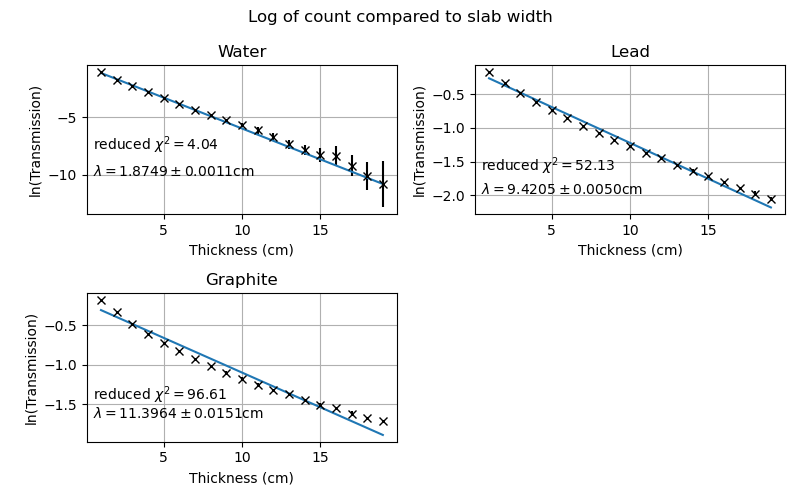

In [ ]:
def find_attenuation_length(length_range, trans_rate, plot_number, plot_title):

    ax = fig_atten.add_subplot(2, 2, plot_number)
    ax.set_title(plot_title)
    ax.set_xlabel('Thickness (cm)')
    ax.set_ylabel('ln(Transmission)')
    ax.grid()
    
    clean_transmission = clean_data(np.column_stack([length_range, trans_rate]))
    log_rate = np.log(clean_transmission[:, 1])
    err_rate = clean_transmission[:, 2]/clean_transmission[:, 1]
    
    coef, covr = np.polyfit(clean_transmission[:, 0], log_rate, 1, w = np.sqrt(clean_transmission[:,1]), cov =True)
    atten_fit = np.polyval(coef, clean_transmission[:, 0])
    fitted_lambda = -1/coef[0]
    err_lambda = abs((covr[0,0] - covr[0,1])/coef[0]**2)

    chi_sqd = chi_squared(atten_fit, log_rate, err_rate)
    red_chi = chi_sqd/(len(log_rate)-2)
    
    ax.errorbar(clean_transmission[:,0], log_rate, yerr=err_rate, fmt = 'x', color = 'k')
    ax.plot(clean_transmission[:,0], atten_fit, '-', label='fit')
    ax.text(0.5,log_rate[17], r'$\lambda = {:.4f} \pm {:.4f}$cm'.format(fitted_lambda, err_lambda))
    ax.text(0.5,log_rate[13], r'reduced $\chi^2 = {:.2f}$'.format(red_chi))
    return None


plt.rcParams["figure.figsize"] = (8,5)
fig_atten = plt.figure()

find_attenuation_length(length_range, water_trans/SAMPLE_SIZE, 1, "Water")
find_attenuation_length(length_range, lead_trans/SAMPLE_SIZE, 2, "Lead")
find_attenuation_length(length_range, graphite_trans/SAMPLE_SIZE, 3, "Graphite")

plt.suptitle("Log of count compared to slab width")
plt.tight_layout()
plt.show()

The chi squared values are high as the errors are far to low, the attenuation lengths are resonable but only water follows a largely linear fit wheras the others have curves. This suggests incorrect theory in estimating errors on the values

In [ ]:
end_time = time()
print("Took ", -start_time+end_time, "s")

Took  20.83002734184265 s
